# Phân tích các yếu tố ảnh hưởng đến rating người dùng trên MovieLens bằng cách kết hợp dữ liệu thông tin phim (TMDb)

In [15]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score


In [16]:
warnings.filterwarnings('ignore')

# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

def get_director(text):
    try:
        data = ast.literal_eval(text)
        for x in data:
            if x['job'] == 'Director': return x['name']
        return np.nan
    except: return np.nan

def get_top_actors(text):
    try:
        data = ast.literal_eval(text)
        return [x['name'] for x in data[:3]]
    except: return []

## Chuẩn bị Dữ liệu (Data Preparation)

In [17]:
# --- 2. TẢI DỮ LIỆU ---
print("Đang tải dữ liệu...")
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

# --- TÍNH ĐIỂM TRUNG BÌNH (AVG_RATING) ---
print("Đang tính toán điểm trung bình cho từng phim...")
movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
movie_targets.columns = ['MovieID', 'avg_rating']

Đang tải dữ liệu...
Đang tính toán điểm trung bình cho từng phim...


In [18]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 2   Age         6040 non-null   int64 
 3   Occupation  6040 non-null   int64 
 4   Zip-code    6040 non-null   object
dtypes: int64(3), object(2)
memory usage: 236.1+ KB


**Các ý nghĩa của từng cột trong bảng Users**:
| Cột (Column)   | Ý nghĩa |
|----------------|---------|
| **UserID**     | Mã định danh của người dùng (ID duy nhất). |
| **Gender**     | Giới tính của người dùng (M/F). |
| **Age**        | Nhóm tuổi hoặc mã tuổi của người dùng (ví dụ: 1 = dưới 18, 18, 25, 35...). |
| **Occupation** | Mã nghề nghiệp của người dùng (một số nguyên biểu diễn từng loại nghề khác nhau). |
| **Zip-code**   | Mã bưu điện (ZIP) hoặc khu vực mà người dùng sinh sống. |


In [19]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MovieID  3883 non-null   int64 
 1   Title    3883 non-null   object
 2   Genres   3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB


**Các ý nghĩa của từng cột trong bảng Movies**:
| Cột (Column) | Ý nghĩa |
|--------------|---------|
| **MovieID**  | ID duy nhất của phim trong hệ thống MovieLens. |
| **Title**    | Tên phim kèm năm phát hành (ví dụ: *Toy Story (1995)*). |
| **Genres**   | Các thể loại phim, phân tách bằng dấu `|` (ví dụ: *Animation|Children's|Comedy*). |


In [20]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 2   Rating     1000209 non-null  int64
 3   Timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


**Các ý nghĩa của từng cột trong bảng Ratings**:
| Cột (Column) | Ý nghĩa |
|--------------|---------|
| **UserID**   | ID người dùng đã đánh giá phim. |
| **MovieID**  | ID của bộ phim được đánh giá. |
| **Rating**   | Điểm đánh giá do người dùng chấm (thường từ 1 đến 5). |
| **Timestamp**| Thời điểm đánh giá (dạng UNIX timestamp – số giây tính từ 1/1/1970). |


In [21]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB ---
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

tmdb_cred.columns = ['movie_id', 'title', 'cast', 'crew']
tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

print(f"Loaded & Merged TMDB: {tmdb_full.shape}")

Loaded & Merged TMDB: (4803, 23)


In [22]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

**Giải thích ý nghĩa của các cột**
| Cột (Column)           | Ý nghĩa |
|------------------------|---------|
| **budget**             | Ngân sách sản xuất phim (USD). |
| **genres**             | Thể loại phim, lưu dưới dạng chuỗi JSON (Action, Comedy…). |
| **homepage**           | Trang web chính thức của bộ phim. |
| **movie_id**           | ID phim trong cơ sở dữ liệu TheMovieDB. |
| **keywords**           | Các từ khóa mô tả nội dung phim. |
| **original_language**  | Ngôn ngữ gốc của phim (ví dụ: `en`, `fr`). |
| **original_title**     | Tên gốc của bộ phim. |
| **overview**           | Tóm tắt nội dung phim. |
| **popularity**         | Mức độ phổ biến của phim trên TMDB. |
| **production_companies** | Danh sách công ty sản xuất phim (JSON string). |
| **production_countries** | Danh sách quốc gia sản xuất phim. |
| **release_date**       | Ngày phát hành phim. |
| **revenue**            | Doanh thu phòng vé (USD). |
| **runtime**            | Thời lượng phim (phút). |
| **spoken_languages**   | Danh sách ngôn ngữ được sử dụng trong phim. |
| **status**             | Tình trạng phát hành (Released, Post Production…). |
| **tagline**            | Slogan/tagline của phim. |
| **title**              | Tên phim phát hành chính thức. |
| **vote_average**       | Điểm đánh giá trung bình trên TMDB. |
| **vote_count**         | Số lượt đánh giá. |
| **tittle_credits**     | Thông tin credit khi merge, có thể là lỗi chính tả của `title_credits`. |
| **cast**               | Danh sách diễn viên của phim (JSON string). |
| **crew**               | Danh sách nhân sự (đạo diễn, biên kịch…) của phim (JSON string). |


In [23]:
# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)


--- Sample Users ---


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [24]:
print("\n--- Sample Movies ---")
movies.head(3)


--- Sample Movies ---


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


In [25]:
print("\n--- Sample Ratings ---")
ratings.head(3)


--- Sample Ratings ---


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


In [26]:
print("\n--- Sample TMDB Credits ---")
tmdb_cred.head(3)


--- Sample TMDB Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


In [27]:
print("\n--- Sample TMDB Movies ---")
tmdb_mov.head(3)


--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


## Tiền xử lý dữ liệu (Data Preprocessing)

### Chuẩn hóa (Data Normalization)

In [28]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB (SỬA LẠI ĐỂ TRÁNH LỖI TITLE) ---
print("Đang tải và xử lý TMDB...")
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

# --- ĐIỂM SỬA QUAN TRỌNG TẠI ĐÂY ---
# Đổi tên cột title của credits thành 'tittle_cr' để không trùng với 'title' của bảng movies
tmdb_cred.columns = ['movie_id', 'tittle_cr', 'cast', 'crew']

tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})

# Merge nội bộ TMDB
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

# Kiểm tra xem cột title có tồn tại không
if 'title' not in tmdb_full.columns:
    # Trường hợp file gốc dùng 'original_title', ta tạo lại cột title
    if 'original_title' in tmdb_full.columns:
        tmdb_full['title'] = tmdb_full['original_title']

print(f"Cột trong TMDB Full: {list(tmdb_full.columns)}")
# Bây giờ chắc chắn đã có cột 'title'

# --- 4. MERGE METADATA (CHẠY LẠI BƯỚC NÀY SẼ KHÔNG CÒN LỖI) ---
print("Đang xử lý Metadata phim...")

# Tạo khóa nối
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# Ghép Movies gốc với TMDB
movies_meta = pd.merge(movies, tmdb_full, on='title_join', how='inner')

# Ghép thêm cột avg_rating (từ bảng movie_targets đã tạo ở bước trước)
movies_meta = pd.merge(movies_meta, movie_targets, on='MovieID', how='inner')

# Trích xuất Director, Actors, Year
movies_meta['director'] = movies_meta['crew'].apply(get_director)
movies_meta['actors_temp'] = movies_meta['cast'].apply(get_top_actors)
actors_df = movies_meta['actors_temp'].apply(pd.Series).iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']
movies_meta = pd.concat([movies_meta, actors_df], axis=1)
movies_meta['release_year'] = movies_meta['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Chọn lọc các cột metadata
cols_meta = [
    'MovieID', 'Title', 'Genres', 'release_year', 'avg_rating',
    'director', 'actor_1', 'actor_2', 'actor_3',
    'budget', 'revenue', 'vote_average', 'vote_count', 'runtime'
]
movies_final_meta = movies_meta[cols_meta]

# --- 5. TẠO DATAFRAME CUỐI CÙNG ---
print("Đang ghép vào bảng Ratings gốc...")
df_final = pd.merge(ratings, movies_final_meta, on='MovieID', how='inner')

print("-" * 30)
print(f"Kích thước cuối cùng: {df_final.shape}")
print("5 dòng đầu tiên:")
print(df_final[['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average']].head())

Đang tải và xử lý TMDB...
Cột trong TMDB Full: ['budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew']
Đang xử lý Metadata phim...
Đang ghép vào bảng Ratings gốc...
------------------------------
Kích thước cuối cùng: (450575, 17)
5 dòng đầu tiên:
   UserID                                   Title  Rating  avg_rating  \
0       1  One Flew Over the Cuckoo's Nest (1975)       5    4.390725   
1       1                     My Fair Lady (1964)       3    4.154088   
2       1                  Erin Brockovich (2000)       4    3.863878   
3       1                          Ben-Hur (1959)       5    4.110795   
4       1  Snow White and the Seven Dwarfs (1937)       4    3.845347   

   vote_average  
0           8.2  
1           7.4 

### Trích xuất đặc trưng (Feature Selection)

In [29]:
movies_merged = movies_meta.copy()

# --- 2. ÁP DỤNG VÀO DATAFRAME ---
print("Đang trích xuất dữ liệu Đạo diễn, Diễn viên và Năm phát hành...")

# 1. Reset các cột nếu đã lỡ chạy trước đó (để tránh lỗi duplicate columns)
cols_to_reset = ['director', 'actor_1', 'actor_2', 'actor_3', 'actors_list', 'release_year']
movies_merged = movies_merged.drop(columns=[c for c in cols_to_reset if c in movies_merged.columns], errors='ignore')

# 2. Trích xuất Đạo diễn (Director)
# Lưu ý: Hàm get_director phải được định nghĩa từ trước
movies_merged['director'] = movies_merged['crew'].apply(get_director)

# 3. Trích xuất Diễn viên (Actors) - CÁCH TỐI ƯU & AN TOÀN HƠN
# Lấy list diễn viên
movies_merged['actors_list'] = movies_merged['cast'].apply(get_top_actors)

# Tách list thành các cột riêng biệt
actors_df = movies_merged['actors_list'].apply(pd.Series)

# Đảm bảo luôn có đủ 3 cột (0, 1, 2) dù dữ liệu thiếu
for i in range(3):
    if i not in actors_df.columns:
        actors_df[i] = np.nan

# Chỉ lấy 3 cột đầu tiên và đổi tên
actors_df = actors_df.iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']

# Ghép vào bảng chính
movies_merged = pd.concat([movies_merged, actors_df], axis=1)

# 4. Trích xuất Năm phát hành (Release Year) từ Title của MovieLens
# Regex: Tìm 4 số nằm trong ngoặc đơn ở cuối chuỗi
movies_merged['release_year'] = movies_merged['Title'].str.extract(r'\((\d{4})\)$')
movies_merged['release_year'] = pd.to_numeric(movies_merged['release_year'], errors='coerce')

# 5. Dọn dẹp cột tạm
movies_merged = movies_merged.drop(columns=['actors_list'], errors='ignore')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print("Các cột hiện có sau khi xử lý Feature Engineering:")
print(list(movies_merged.columns))

print("\n5 dòng dữ liệu mẫu (Kiểm tra Đạo diễn, Diễn viên, Năm):")
cols_check = ['Title', 'release_year', 'director', 'actor_1', 'Genres']
print(movies_merged[cols_check].head())

Đang trích xuất dữ liệu Đạo diễn, Diễn viên và Năm phát hành...
------------------------------
Các cột hiện có sau khi xử lý Feature Engineering:
['MovieID', 'Title', 'Genres', 'title_join', 'budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew', 'avg_rating', 'actors_temp', 'director', 'actor_1', 'actor_2', 'actor_3', 'release_year']

5 dòng dữ liệu mẫu (Kiểm tra Đạo diễn, Diễn viên, Năm):
                     Title  release_year         director          actor_1  \
0         Toy Story (1995)          1995    John Lasseter        Tom Hanks   
1         GoldenEye (1995)          1995  Martin Campbell   Pierce Brosnan   
2             Nixon (1995)          1995     Oliver Stone  Anthony Hopkins   
3  Cutthroat Island (1995)        

### Tích hợp dữ liệu (Data Integration)

In [30]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim (Metadata)
# Chúng ta chỉ giữ lại những thông tin có giá trị phân tích
cols_to_keep = [
    'MovieID', 'Title',             # Định danh phim
    'Genres', 'release_year',       # Thông tin cơ bản
    'director', 'actor_1', 'actor_2', 'actor_3', # Ekip làm phim
    'budget', 'revenue',            # Tài chính
    'vote_average', 'vote_count',   # Đánh giá từ TMDB
    'avg_rating'                    # Đánh giá trung bình từ MovieLens (Đã tính ở bước trước)
]

# Lọc để chỉ lấy các cột thực sự tồn tại trong movies_merged (tránh lỗi nếu thiếu cột nào đó)
existing_cols = [c for c in cols_to_keep if c in movies_merged.columns]
movies_lean = movies_merged[existing_cols]

# 2. Thực hiện Merge cuối cùng (Big Merge)
# Ghép bảng Ratings (1 triệu dòng) với bảng Metadata phim đã lọc gọn
# Dùng 'inner' để chỉ giữ lại các rating của những phim ĐÃ CÓ thông tin từ TMDB
print("Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...")
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print(f"Tổng số lượt đánh giá gốc (Ratings): {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge (Full Data): {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")
print("-" * 30)

# Xem 5 dòng dữ liệu hoàn chỉnh để đảm bảo bạn có đủ 3 loại điểm số
# 1. Rating: Điểm do người dùng này chấm
# 2. avg_rating: Điểm trung bình của phim trên MovieLens
# 3. vote_average: Điểm trung bình của phim trên TMDB
print("5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):")
cols_check = ['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average', 'director']
print(full_data[cols_check].head())

Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...
------------------------------
Tổng số lượt đánh giá gốc (Ratings): 1000209
Tổng số dòng dữ liệu sau khi merge (Full Data): 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634
------------------------------
5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):
   UserID                                   Title  Rating  avg_rating  \
0       1  One Flew Over the Cuckoo's Nest (1975)       5    4.390725   
1       1                     My Fair Lady (1964)       3    4.154088   
2       1                  Erin Brockovich (2000)       4    3.863878   
3       1                          Ben-Hur (1959)       5    4.110795   
4       1  Snow White and the Seven Dwarfs (1937)       4    3.845347   

   vote_average           director  
0           8.2       Miloš Forman  
1           7.4       George Cukor  
2           7.1  Steven Soderbergh  
3           5.3  Timur Bekmambetov  
4           6.9         David Hand  


In [31]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450575 entries, 0 to 450574
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   UserID        450575 non-null  int64  
 1   MovieID       450575 non-null  int64  
 2   Rating        450575 non-null  int64  
 3   Timestamp     450575 non-null  int64  
 4   Title         450575 non-null  object 
 5   Genres        450575 non-null  object 
 6   release_year  450575 non-null  int64  
 7   director      450535 non-null  object 
 8   actor_1       450535 non-null  object 
 9   actor_2       450535 non-null  object 
 10  actor_3       450535 non-null  object 
 11  budget        450575 non-null  int64  
 12  revenue       450575 non-null  int64  
 13  vote_average  450575 non-null  float64
 14  vote_count    450575 non-null  int64  
 15  avg_rating    450575 non-null  float64
dtypes: float64(2), int64(8), object(6)
memory usage: 55.0+ MB


In [32]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347
5,1,2791,4,978302188,Airplane! (1980),Comedy,1980,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,1074,3.971115
6,1,2018,4,978301777,Bambi (1942),Animation|Children's,1942,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,1405,3.738540
7,1,2797,4,978302039,Big (1988),Comedy|Fantasy,1988,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,993,3.855801
8,1,1270,5,978300055,Back to the Future (1985),Comedy|Sci-Fi,1985,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,6079,3.990321
9,1,527,5,978824195,Schindler's List (1993),Drama|War,1993,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,4329,4.510417


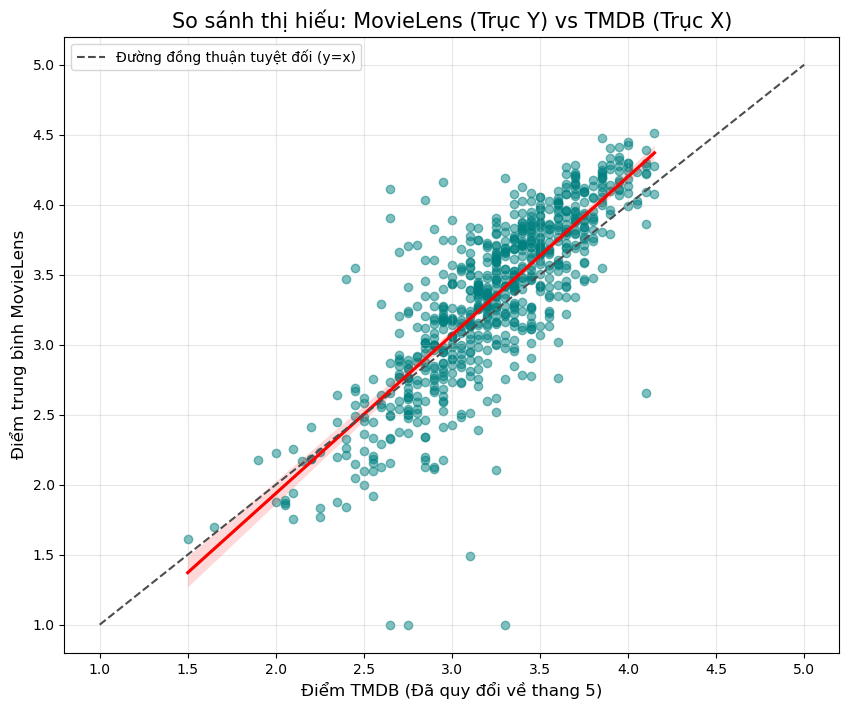

--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
95              Ben-Hur (1959)  4.110795             2.65
347        Ghostbusters (1984)  3.905548             2.65
701     Shall We Dance? (1937)  4.165714             2.95
29   All the King's Men (1949)  4.033613             2.85
369  Gulliver's Travels (1939)  3.547009             2.45

--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
834          Underworld (1997)  1.000000             3.30
342         Get Over It (1996)  1.000000             2.75
718           Sleepover (1995)  1.000000             2.65
222  Digimon: The Movie (2000)  1.488372             3.10
628              Psycho (1998)  2.651515             4.10


In [33]:
# --- BƯỚC 1: GOM NHÓM DỮ LIỆU THEO PHIM ---
# Tính điểm trung bình thực tế của người dùng MovieLens cho từng phim
movie_comparison = full_data.groupby('Title').agg({
    'Rating': 'mean',          # Điểm trung bình MovieLens (1-5)
    'vote_average': 'first',   # Điểm TMDB (0-10) - Lấy giá trị đầu tiên vì nó giống nhau cho cả phim
    'vote_count': 'first'   # Lấy số lượng vote để lọc bớt phim ít người xem
}).reset_index()

# Đổi tên cho dễ gọi
movie_comparison.columns = ['Title', 'ML_Score', 'TMDB_Score', 'Vote_Count']

# --- BƯỚC 2: CHUẨN HÓA THANG ĐIỂM ---
# Chuyển TMDB từ thang 10 về thang 5 để so sánh công bằng
movie_comparison['TMDB_Score_Norm'] = movie_comparison['TMDB_Score'] / 2

# Lọc các phim có ít nhất 50 lượt đánh giá để biểu đồ không bị nhiễu
movie_comparison = movie_comparison[movie_comparison['Vote_Count'] > 50]

# --- BƯỚC 3: VẼ BIỂU ĐỒ TƯƠNG QUAN ---
plt.figure(figsize=(10, 8))

# Vẽ Scatter plot kèm đường hồi quy (Regplot)
sns.regplot(x='TMDB_Score_Norm', y='ML_Score', data=movie_comparison,
            scatter_kws={'alpha': 0.5, 'color': 'teal'},
            line_kws={'color': 'red'})

# Vẽ đường chéo y=x (Đường tham chiếu sự hoàn hảo)
# Nếu điểm nằm trên đường này: MovieLens và TMDB chấm y hệt nhau
plt.plot([1, 5], [1, 5], ls="--", c=".3", label="Đường đồng thuận tuyệt đối (y=x)")

plt.title('So sánh thị hiếu: MovieLens (Trục Y) vs TMDB (Trục X)', fontsize=15)
plt.xlabel('Điểm TMDB (Đã quy đổi về thang 5)', fontsize=12)
plt.ylabel('Điểm trung bình MovieLens', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- BƯỚC 4: TÌM NHỮNG PHIM "GÂY TRANH CÃI" NHẤT ---
# Tính độ lệch (Gap)
movie_comparison['Diff'] = movie_comparison['ML_Score'] - movie_comparison['TMDB_Score_Norm']

print("--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=False)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

print("\n--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=True)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

### Làm sạch dữ liệu (Data Cleaning)

In [34]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID           0
MovieID          0
Rating           0
Timestamp        0
Title            0
Genres           0
release_year     0
director        40
actor_1         40
actor_2         40
actor_3         40
budget           0
revenue          0
vote_average     0
vote_count       0
avg_rating       0
dtype: int64

In [35]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 16)
 Số dòng bị thiếu: 
UserID          0
MovieID         0
Rating          0
Timestamp       0
Title           0
Genres          0
release_year    0
director        0
actor_1         0
actor_2         0
actor_3         0
budget          0
revenue         0
vote_average    0
vote_count      0
avg_rating      0
dtype: int64


In [36]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

np.int64(0)

In [37]:
# --- LỌC DỮ LIỆU CHẤT LƯỢNG CAO (CLEANING DATA) ---

print(f"Số lượng dòng dữ liệu ban đầu: {full_data.shape[0]}")

# Áp dụng 3 điều kiện lọc cùng lúc:
# 1. vote_count > 50: Bỏ qua các phim quá ít người quan tâm trên TMDB (tránh nhiễu)
# 2. budget > 10000: Bỏ qua phim không có số liệu ngân sách hoặc ngân sách quá thấp (lỗi nhập liệu)
# 3. revenue > 10000: Bỏ qua phim không có số liệu doanh thu

full_data = full_data[
    (full_data['vote_count'] > 50) &
    (full_data['budget'] > 10000) &
    (full_data['revenue'] > 10000)
]

# --- KIỂM TRA KẾT QUẢ SAU KHI LỌC ---
print("-" * 30)
print(f"Số lượng dòng sau khi lọc: {full_data.shape[0]}")
print(f"-> Đã loại bỏ: {full_data.shape[0] - full_data.shape[0]} dòng dữ liệu rác/thiếu thông tin.")

# Xem thống kê nhanh về tài chính của tập dữ liệu sạch
print("\nThống kê dữ liệu tài chính sau khi lọc:")
print(full_data[['budget', 'revenue', 'vote_count']].describe().apply(lambda s: s.apply('{0:.2f}'.format)))

Số lượng dòng dữ liệu ban đầu: 450495
------------------------------
Số lượng dòng sau khi lọc: 397975
-> Đã loại bỏ: 0 dòng dữ liệu rác/thiếu thông tin.

Thống kê dữ liệu tài chính sau khi lọc:
             budget        revenue vote_count
count     397975.00      397975.00  397975.00
mean    37087587.03   180600388.37    1467.37
std     36699190.83   210367425.44    1606.35
min        12000.00      120000.00      52.00
25%     10500000.00    39846344.00     395.00
50%     25000000.00   115101622.00     840.00
75%     55000000.00   254700832.00    1783.00
max    207000000.00  1845034188.00    9413.00


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

In [38]:
full_data.describe().T.style.format("{:.2f}").background_gradient(cmap = "magma")

,count,mean,std,min,25%,50%,75%,max
UserID,397975.00,3005.05,1729.01,1.00,1496.00,3038.00,4451.00,6040.00
MovieID,397975.00,1796.27,1071.55,1.00,1028.00,1676.00,2699.00,3949.00
Rating,397975.00,3.63,1.11,1.00,3.00,4.00,4.00,5.00
Timestamp,397975.00,972107846.17,11854877.66,956703954.00,965306212.00,973051290.00,975200680.50,1046454443.00
release_year,397975.00,1988.62,12.98,1926.00,1984.00,1994.00,1997.00,2000.00
budget,397975.00,37087587.03,36699190.83,12000.00,10500000.00,25000000.00,55000000.00,207000000.00
revenue,397975.00,180600388.37,210367425.44,120000.00,39846344.00,115101622.00,254700832.00,1845034188.00
vote_average,397975.00,6.86,0.80,3.00,6.40,6.90,7.50,8.30
vote_count,397975.00,1467.37,1606.35,52.00,395.00,840.00,1783.00,9413.00
avg_rating,397975.00,3.63,0.51,1.00,3.35,3.71,4.03,4.51


Sau bước làm sạch dữ liệu, bộ dữ liệu còn 397.975 bản ghi — vẫn là một quy mô rất lớn, đảm bảo độ tin cậy cho các phân tích tiếp theo. Việc loại bỏ các giá trị nhiễu và thiếu thông tin đã giúp dữ liệu phản ánh sát hơn thực tế thị trường và hành vi người xem.

Đối với dữ liệu đánh giá, điểm Rating trung bình tăng nhẹ lên 3.63 trong khi trung vị vẫn giữ ở mức 4.0. Điều này cho thấy mức độ hài lòng chung có xu hướng tích cực hơn sau khi loại bỏ các phim ít người xem hoặc chất lượng thấp. Đặc biệt, số lượng tối thiểu lượt đánh giá hiện là 52, thay vì 0 như trước. Điều này đảm bảo rằng mỗi bộ phim trong dữ liệu đều đã nhận được đánh giá từ ít nhất 52 người, từ đó tăng tính đáng tin cậy của dữ liệu và hạn chế hiện tượng đánh giá sai lệch.

Ở khía cạnh tài chính, phân phối của ngân sách và doanh thu thể hiện rõ dạng lệch phải, đặc trưng phổ biến của ngành điện ảnh. Ngân sách trung bình khoảng 37 triệu USD, cao hơn đáng kể so với trung vị 25 triệu USD. Doanh thu cũng cho thấy sự chênh lệch lớn khi trung bình đạt 180 triệu USD trong khi trung vị chỉ khoảng 115 triệu USD. Điều này chứng minh sự tồn tại của nhóm phim bom tấn — tuy chiếm tỷ lệ nhỏ nhưng có sức ảnh hưởng mạnh, làm kéo mức trung bình lên cao. Hơn nữa, việc các giá trị tài chính nhỏ nhất đã được làm sạch và không còn dạng phi thực tế như 0 USD giúp các phân tích tiếp theo trở nên chính xác và hợp lý hơn.

Cuối cùng, dữ liệu thời gian trải dài từ năm 1926 đến 2000, phản ánh một giai đoạn phát triển dài của ngành công nghiệp điện ảnh. Trung bình năm phát hành rơi vào khoảng 1989, cho thấy phần lớn các phim trong mẫu là phim hiện đại, gần với thị hiếu và thói quen xem phim của người dùng MovieLens. Điều này cũng đồng nghĩa rằng các phân tích tiếp theo mang tính đại diện cao đối với xu hướng thị trường giải trí cuối thế kỷ 20.

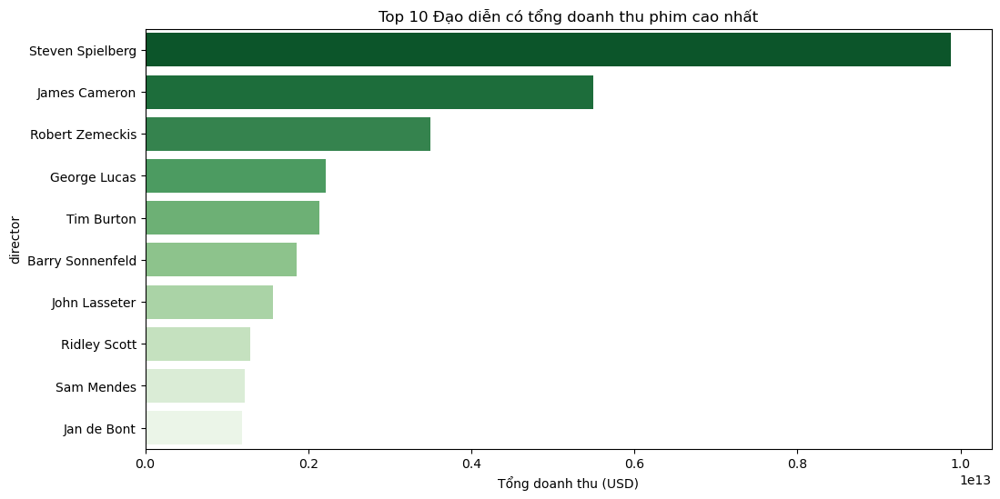

In [39]:
# Gom nhóm theo Đạo diễn và tính tổng doanh thu
# Chỉ lấy những dòng có revenue (tự động bỏ NaN)
director_revenue = full_data.groupby('director')['revenue'].sum().sort_values(ascending=False).head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
sns.barplot(x=director_revenue.values, y=director_revenue.index, palette='Greens_r')
plt.title('Top 10 Đạo diễn có tổng doanh thu phim cao nhất')
plt.xlabel('Tổng doanh thu (USD)')
plt.show()

Biểu đồ thanh ngang minh họa Top 10 đạo diễn dẫn đầu về tổng doanh thu phòng vé trong tập dữ liệu, cho thấy sự phân hóa mạnh mẽ về hiệu suất thương mại giữa các nhà làm phim hàng đầu. Nổi bật nhất là sự thống trị tuyệt đối của Steven Spielberg với tổng doanh thu tiệm cận mốc 10 tỷ USD. Cột dữ liệu của ông dài vượt trội, gần gấp đôi so với người đứng thứ hai, khẳng định vị thế "Vua phòng vé" và khả năng tạo ra các tác phẩm đại chúng xuyên suốt nhiều thập kỷ.

Đứng ở vị trí thứ hai là James Cameron với tổng doanh thu đạt khoảng hơn 5.5 tỷ USD. Mặc dù số lượng phim của ông thường ít hơn Spielberg, nhưng hiệu suất doanh thu trên từng đầu phim (như Titanic, Avatar) là cực kỳ lớn giúp ông giữ vững vị trí á quân. Theo sau là Robert Zemeckis ở vị trí thứ ba với khoảng 3.5 tỷ USD, đại diện cho nhóm đạo diễn gạo cội có phong cách làm phim ăn khách bền vững.

Nhóm các đạo diễn còn lại như George Lucas và Tim Burton duy trì mức doanh thu ổn định trong khoảng hơn 2 tỷ USD. Nửa dưới của Top 10 bao gồm Barry Sonnenfeld, John Lasseter, Ridley Scott, Sam Mendes và Jan de Bont với mức doanh thu dao động từ 1.2 đến 1.8 tỷ USD. Nhìn chung, biểu đồ phản ánh rõ quy luật "Winner-takes-all" trong ngành công nghiệp điện ảnh, nơi một nhóm nhỏ các đạo diễn siêu sao (Tier 1) nắm giữ phần lớn thị phần doanh thu so với phần còn lại của thị trường.

#### Phân tích biến mục tiêu Rating
1. Phân tích đơn biến

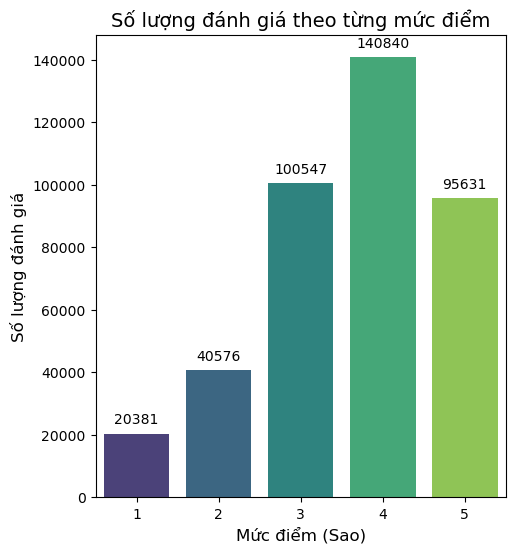

In [40]:
# Thiết lập kích thước tổng thể
plt.figure(figsize=(18, 6))

# --- BIỂU ĐỒ 1: PHÂN PHỐI SỐ LƯỢNG (COUNT PLOT) ---
# Giúp bạn thấy rõ số lượng đánh giá cho từng mức điểm (1-5 sao)
plt.subplot(1, 3, 1)
ax = sns.countplot(x='Rating', data=full_data, palette='viridis')
plt.title('Số lượng đánh giá theo từng mức điểm', fontsize=14)
plt.xlabel('Mức điểm (Sao)', fontsize=12)
plt.ylabel('Số lượng đánh giá', fontsize=12)

# Thêm số liệu cụ thể lên đầu cột để dễ đọc
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points')

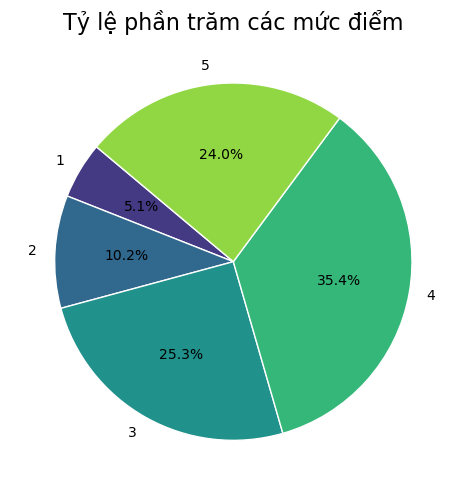

In [41]:
# --- BIỂU ĐỒ 2: TỶ TRỌNG PHẦN TRĂM (PIE CHART) ---
plt.figure(figsize=(14, 5))   # ⬅ tăng kích thước toàn hình

plt.subplot(1, 3, 2)
rating_counts = full_data['Rating'].value_counts().sort_index()

plt.pie(
    rating_counts,
    labels=rating_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('viridis', 5),
    wedgeprops={'edgecolor': 'white'}
)

plt.title('Tỷ lệ phần trăm các mức điểm', fontsize=16)  # tăng font luôn
plt.tight_layout()


In [42]:
fig = px.histogram(full_data,x='Rating',
                   labels={'Rating': 'Điểm số', 'count': 'Số lượng'},
                   title="Biểu đồ phân phối điểm số")
fig.update_yaxes(title="Số lượng")
fig.update_traces(
    hovertemplate="Điểm số = %{x}<br>Số lượng = %{y}"
)
fig.show()

Dựa trên biểu đồ phân phối số lượng đánh giá theo từng mức điểm, có thể nhận định rằng dữ liệu mang tính lệch trái rõ rệt, khi phần lớn người dùng tập trung chấm điểm cao. Cụ thể, mức điểm 4 sao xuất hiện nhiều nhất, chiếm hơn 140 nghìn lượt đánh giá, tiếp theo là 5 sao với hơn 95 nghìn lượt. Trong khi đó, các mức điểm thấp (1–2 sao) xuất hiện rất ít. Điều này cho thấy xu hướng đánh giá tích cực là chủ đạo.

Kết quả này phản ánh đúng tâm lý người dùng trong hệ thống đánh giá phim: họ có xu hướng xem những bộ phim phù hợp với sở thích nên thường cho điểm cao. Ngược lại, các bộ phim dở hoặc không phù hợp thường bị bỏ dở, dẫn đến việc người xem không đánh giá hoặc không chấm quá thấp. Vì vậy, điểm 3 sao không thực sự đại diện mức trung bình, mà mang ý nghĩa thiên về mức "trung bình thấp". Một bộ phim muốn được xem là “hay” cần đạt mức 4–5 sao.

In [43]:
# --- IN RA CON SỐ THỐNG KÊ CỤ THỂ ---
mean_rating = full_data['Rating'].mean()
median_rating = full_data['Rating'].median()
print(f"Điểm đánh giá trung bình (Mean): {mean_rating:.2f}")
print(f"Điểm đánh giá trung vị (Median): {median_rating}")

Điểm đánh giá trung bình (Mean): 3.63
Điểm đánh giá trung vị (Median): 4.0


Hai giá trị Mean = 3.63 và Median = 4.0 cho thấy người dùng có xu hướng chấm điểm khá cao cho các bộ phim. Việc trung vị (4.0) lớn hơn trung bình (3.63) chứng tỏ phần lớn đánh giá tập trung ở mức tốt (4–5 sao), trong khi một số ít đánh giá thấp đã kéo trung bình giảm xuống. Trong trường hợp này, Median = 4.0 là giá trị đáng tin cậy hơn để đại diện cho mức độ hài lòng thực tế, vì nó phản ánh điểm điển hình mà phần lớn người dùng chấm, thay vì bị ảnh hưởng bởi một số ít đánh giá cực thấp. Do đó, khi đánh giá chất lượng phim của dataset, mức điểm phổ biến và đáng tin nhất chính là 4 sao.

2. Phân tích đa biến

Trả lời câu hỏi: "Phim càng nhiều người chấm điểm (càng nổi) thì điểm càng cao, hay phim "bom xịt" mới ít người chấm?" thông qua mối tương quan giữa "Độ nổi tiếng" và "Chất lượng"


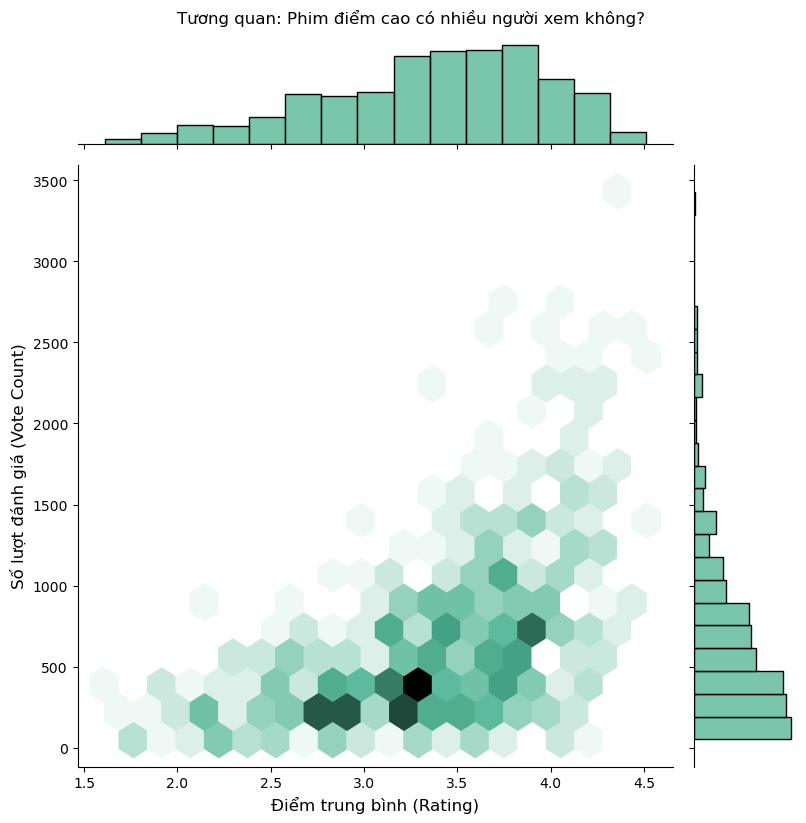

In [44]:
# Biểu đồ Joint Plot: Tương quan giữa "Độ nổi tiếng" và "Chất lượng"
# Tạo một biến đếm số lượng rating cho mỗi phim (Vote Count)
movie_stats = full_data.groupby('Title').agg({'Rating': ['mean', 'count']})
movie_stats.columns = ['avg_rating', 'vote_count']

# Lọc bớt các phim quá ít rating (< 50) để biểu đồ đỡ nhiễu
popular_movies = movie_stats[movie_stats['vote_count'] > 50]

# Vẽ Jointplot kiểu 'hex' (tổ ong) nhìn rất ngầu
# kind='hex' giúp nhìn rõ mật độ tập trung hơn là scatter chấm bi thông thường
g = sns.jointplot(x='avg_rating', y='vote_count', data=popular_movies,
                  kind='hex', color='#4CB391', height=8)

g.fig.suptitle('Tương quan: Phim điểm cao có nhiều người xem không?', y=1.02)
g.set_axis_labels('Điểm trung bình (Rating)', 'Số lượt đánh giá (Vote Count)', fontsize=12)
plt.show()

Biểu đồ Jointplot (dạng tổ ong) cung cấp một góc nhìn sâu sắc về quy luật đào thải của điện ảnh. Phần lớn các điểm dữ liệu tập trung ở vùng điểm trung bình (3.0 - 3.5) với số lượng đánh giá thấp, phản ánh thực tế rằng đa số các bộ phim đều ở mức thường thường bậc trung và ít được chú ý. Tuy nhiên, khi quan sát các bộ phim có lượng tương tác "khủng" (trên 2000 lượt đánh giá), chúng ta thấy chúng hầu hết đều nằm ở vùng điểm số cao (trên 3.5). Hiện tượng này khẳng định mối tương quan thuận chiều giữa chất lượng và độ nổi tiếng: phim dở thường bị lãng quên nhanh chóng, trong khi chỉ những tác phẩm thực sự chất lượng mới đủ sức tạo ra hiệu ứng đám đông và thu hút lượng người xem lớn.

Trả lời câu hỏi: Đàn ông và Phụ nữ, ai "khắt khe" hơn khi chấm điểm? Boxplot bình thường không cho thấy mật độ, nhưng Violin plot thì có.

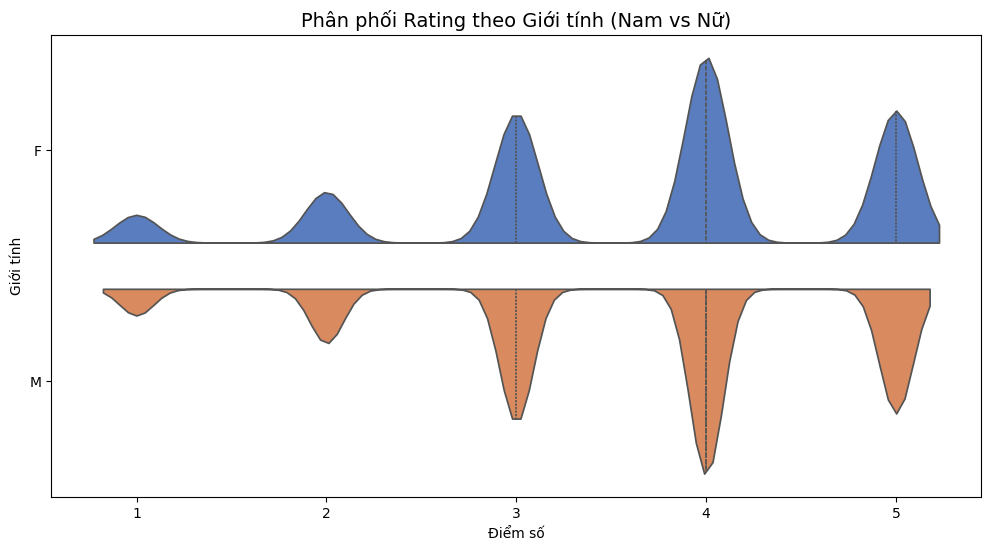

In [45]:
# Biểu đồ Violin Plot: So sánh Rating theo Giới tính/Độ tuổi
full_data = pd.merge(full_data, users[['UserID', 'Gender', 'Age']], on='UserID', how='left')
plt.figure(figsize=(12, 6))

# Vẽ Violin plot
# split=True: Chia đôi cây đàn, một nửa là Nam (M), một nửa là Nữ (F) để dễ so sánh
sns.violinplot(x='Rating', y='Gender', data=full_data,
               palette='muted', split=True, inner='quartile')

plt.title('Phân phối Rating theo Giới tính (Nam vs Nữ)', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Giới tính')
plt.show()

Về sự khác biệt hành vi giữa các nhóm giới tính Biểu đồ Violin (Violin Plot) cung cấp cái nhìn so sánh thú vị giữa người dùng Nam và Nữ. Mặc dù hình dáng phân phối tổng thể khá tương đồng (đều phình to ở mức 3-4 sao), nhưng có những sự khác biệt tinh tế. Nhóm người dùng Nữ thể hiện sự quyết đoán và hào phóng hơn, biểu hiện qua phần đỉnh nhọn và phình to hơn ở mức 4-5 sao. Trong khi đó, nhóm Nam giới có phổ đánh giá trải rộng hơn một chút xuống các mức điểm thấp (2-3 sao). Tuy nhiên, kết luận chung là giới tính không phải yếu tố gây phân cực sâu sắc về điểm số; cả hai giới đều chia sẻ chung một gu thẩm mỹ "dễ chịu" đối với các bộ phim họ chọn xem.

Trả lời câu hỏi: Thể loại phim nào được ưu ái nhất?

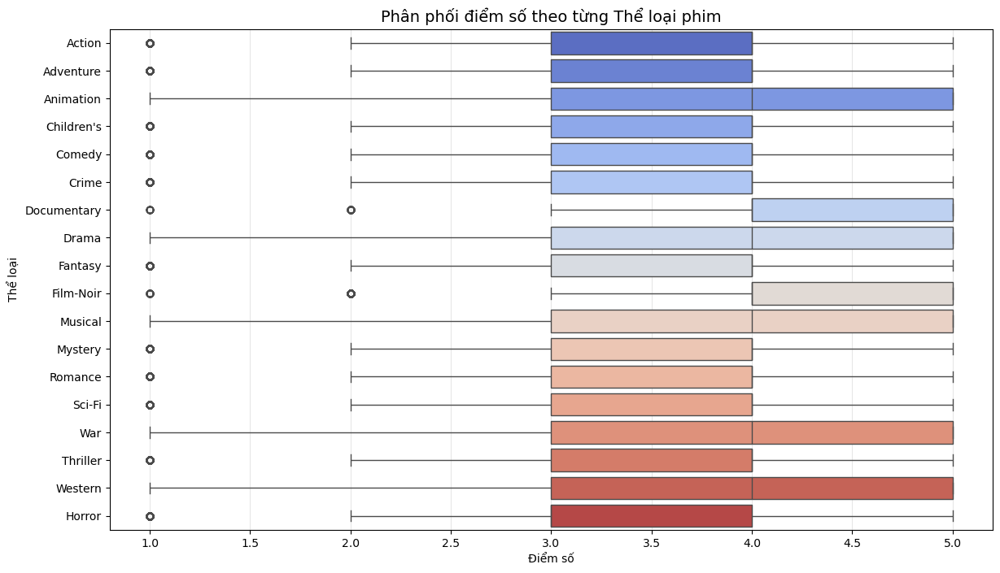

In [46]:
# Biểu đồ Heatmap: Ma trận Thể loại vs. Rating
# 1. Tách thể loại (Explode Genres) - Bước này hơi nặng chút
# Tạo bản sao để không ảnh hưởng dữ liệu gốc
genres_df = full_data[['MovieID', 'Rating', 'Genres']].copy()
# Chuyển chuỗi "Action|Comedy" thành list ["Action", "Comedy"]
genres_df['Genres'] = genres_df['Genres'].str.split('|')
# Bung nén (Explode): Biến 1 dòng chứa list thành nhiều dòng
genres_exploded = genres_df.explode('Genres')

# 2. Vẽ Boxplot sắp xếp theo điểm trung vị
plt.figure(figsize=(14, 8))

# Tính thứ tự sắp xếp: Thể loại nào có điểm trung vị cao nhất xếp trước
order = genres_exploded.groupby('Genres')['Rating'].median().sort_values(ascending=False).index

sns.boxplot(x='Rating', y='Genres', data=genres_exploded,
            order=order, palette='coolwarm')

plt.title('Phân phối điểm số theo từng Thể loại phim', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Thể loại')
plt.grid(axis='x', alpha=0.3)
plt.show()

Biểu đồ thể hiện sự phân bố điểm đánh giá theo từng thể loại phim và cho thấy sự khác biệt khá rõ về mức độ được yêu thích giữa các dòng phim. Nhìn chung, nhóm thể loại như Documentary, Film-Noir, Drama hay War có điểm trung vị cao nhất, cho thấy những bộ phim thuộc nhóm này thường được đánh giá nghiêm túc và chất lượng nội dung cao, dù có thể không phổ biến về mặt thương mại. Đây là những thể loại thường thu hút nhóm khán giả chuyên sâu và có tiêu chuẩn đánh giá rõ ràng.

Ngược lại, Horror là thể loại có điểm trung vị thấp nhất. Điều này phản ánh tính chất phân cực của phim kinh dị—đa số khán giả dễ thất vọng nếu nội dung không đủ mới mẻ, hoặc phim thiên về giải trí hù dọa thay vì cốt truyện sâu. Các thể loại phổ biến như Action, Adventure hay Sci-Fi có mức điểm trung bình khá ổn định quanh vùng 3.3–3.8, thể hiện tính đại chúng và phù hợp thị hiếu rộng hơn.

Đáng chú ý, hầu hết các thể loại đều có vài giá trị ngoại lai (outliers), chứng tỏ mỗi nhóm vẫn tồn tại cả phim rất kém và phim xuất sắc, tạo nên độ chênh nhất định trong phân phối điểm. Tổng thể, biểu đồ cho thấy sự phân hóa thú vị giữa các thể loại: những nhóm có ít người xem lại thường được đánh giá cao, trong khi các thể loại đại chúng ghi nhận mức điểm vừa phải hơn nhưng ổn định hơn.

Đang phân tích tương quan trên 617 bộ phim với các biến:
['release_year', 'budget', 'revenue', 'vote_average', 'vote_count', 'avg_rating', 'Age']


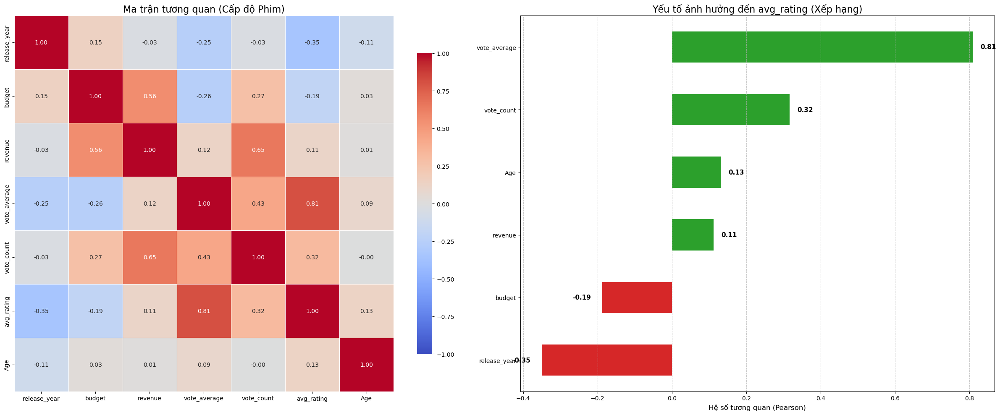

In [47]:
# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU CẤP ĐỘ PHIM (QUAN TRỌNG) ---
# Chỉ giữ lại mỗi phim 1 dòng để tính toán các chỉ số vĩ mô (Budget, Revenue...)
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()

# --- BƯỚC 2: TỰ ĐỘNG CHỌN CỘT SỐ ---

# 1. Lấy tất cả cột số
all_numeric_cols = df_movie_scope.select_dtypes(include=[np.number]).columns.tolist()

# 2. Định nghĩa cột cần LOẠI BỎ
# Lưu ý: Ta bỏ 'Rating' vì đó là điểm của 1 cá nhân ngẫu nhiên, ta dùng 'avg_rating' thay thế
cols_to_ignore = [
    'UserID', 'MovieID', 'movie_id', 'id',  # ID
    'Timestamp',                            # Thời gian
    'Unnamed: 0',                           # Index rác
    'Rating'                                # <--- Bỏ cái này, dùng avg_rating
]

# 3. Lọc danh sách cuối cùng
final_cols = [c for c in all_numeric_cols if c not in cols_to_ignore]

print(f"Đang phân tích tương quan trên {df_movie_scope.shape[0]} bộ phim với các biến:")
print(final_cols)

# 4. Tính ma trận tương quan
corr_matrix = df_movie_scope[final_cols].corr()

# --- BƯỚC 3: VẼ BIỂU ĐỒ ---

fig_height = 10 if len(final_cols) < 15 else 15
fig, ax = plt.subplots(1, 2, figsize=(24, fig_height))

# 3.1. Vẽ Heatmap (Bên trái)
sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            vmin=-1, vmax=1,
            linewidths=0.5,
            ax=ax[0],
            cbar_kws={"shrink": .8})
ax[0].set_title('Ma trận tương quan (Cấp độ Phim)', fontsize=16)

# 3.2. Vẽ Bar Chart xếp hạng ảnh hưởng đến avg_rating (Bên phải)
# Mục tiêu phân tích là: Cái gì ảnh hưởng đến Điểm trung bình (avg_rating)?
target_col = 'avg_rating'

if target_col in corr_matrix.columns:
    target_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=True)

    # Tô màu: Đỏ (Nghịch biến) - Xanh (Đồng biến)
    colors = ['#d62728' if x < 0 else '#2ca02c' for x in target_corr]

    target_corr.plot(kind='barh', color=colors, ax=ax[1])

    # Trang trí
    ax[1].set_title(f'Yếu tố ảnh hưởng đến {target_col} (Xếp hạng)', fontsize=16)
    ax[1].set_xlabel('Hệ số tương quan (Pearson)', fontsize=12)
    ax[1].grid(axis='x', linestyle='--', alpha=0.7)

    # Thêm nhãn số liệu
    for index, value in enumerate(target_corr):
        offset = 0.02 if value >= 0 else -0.08 # Chỉnh offset để số không đè lên cột
        ax[1].text(value + offset, index, f'{value:.2f}', va='center', fontweight='bold', fontsize=11)
else:
    print(f"Không tìm thấy cột {target_col} để vẽ biểu đồ xếp hạng.")

plt.tight_layout()
plt.show()

Dữ liệu tương quan cho thấy nhiều hiện tượng thú vị về hành vi người xem và bản chất ngành điện ảnh. Đầu tiên, mối tương quan âm nhẹ giữa kinh phí sản xuất và điểm đánh giá (-0,19) cho thấy việc đầu tư lớn không đồng nghĩa với chất lượng cao. Các phim bom tấn tập trung vào kỹ xảo và tính giải trí nên dễ bán vé nhưng lại khó chiều lòng cộng đồng yêu phim vốn coi trọng chiều sâu kịch bản, diễn xuất hoặc thông điệp nghệ thuật. Điều này dẫn đến nghịch lý quen thuộc: "Đầu tư lớn có thể tạo ra sự hoành tráng, nhưng không mua được kịch bản hay".

Ngược lại, sự tương quan cực mạnh (+0,81) giữa điểm trung bình của TMDB và MovieLens thể hiện sự đồng nhất về thị hiếu người xem trên quy mô toàn cầu. Đây là tín hiệu rất tốt về độ tin cậy của dữ liệu, đồng thời cho thấy việc ghép dữ liệu là hoàn toàn hợp lý. Một bộ phim hay thì dù được đánh giá ở cộng đồng Mỹ hay quốc tế đều nhận được sự đánh giá tích cực.

Một hiện tượng ngược dòng đáng chú ý xuất hiện ở biến thời gian phát hành. Phim ra mắt càng muộn thì điểm đánh giá lại có xu hướng thấp hơn (tương quan -0,35). Tuy nhiên, điều này không có nghĩa phim hiện đại kém chất lượng hơn. Đây là trường hợp điển hình của "hiệu ứng kẻ sống sót": chỉ những tác phẩm xuất sắc của thời kỳ trước mới được lưu giữ và đánh giá cho tới ngày nay, trong khi các tác phẩm tầm thường đã biến mất khỏi hệ thống, khiến các giá trị trung bình của phim cũ cao hơn.

Mặt khác, kết quả xác nhận quy luật kinh tế quen thuộc: “rủi ro cao, lợi nhuận cao”. Mối liên hệ giữa ngân sách và doanh thu ở mức mạnh (+0,65), phản ánh hiệu quả đầu tư của các hãng phim. Các tác phẩm kinh phí lớn đi kèm chiến dịch quảng bá mạnh mẽ, số lượng suất chiếu rộng rãi và độ phủ truyền thông lớn, từ đó mang về doanh thu cao.

Cuối cùng, chất lượng và doanh thu có liên hệ nhưng không mạnh (tương quan +0,11). Điều này có thể hiểu rằng phim hay thường có doanh thu tốt hơn, nhưng chưa đủ mạnh để đưa ra kết luận ngược lại. Những phim nghệ thuật chất lượng cao thường kén khán giả, doanh thu thấp; còn phim giải trí chỉ cần hiệu ứng truyền thông cũng có thể mang về doanh thu lớn. Điều này cho thấy doanh thu phụ thuộc nhiều hơn vào chiến lược marketing và sức hút thương hiệu, thay vì nội dung thuần túy.

## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

### 2. Yếu tố Nội dung & Cấu trúc
Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

#### a. Thể loại

In [48]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline


# Models
# from sklearn.linear_model import LinearRegression, Ridge, Lasso
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
# from sklearn.neighbors import KNeighborsRegressor

from cuml.linear_model import LinearRegression, Ridge, Lasso
from cuml.ensemble import RandomForestRegressor
from cuml.neighbors import KNeighborsRegressor
import cupy as cp


ModuleNotFoundError: No module named 'cuml'

In [49]:
pip install cuml-cu12 --extra-index-url=https://pypi.nvidia.com


Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.org/simple, https://pypi.nvidia.com
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [72 lines of output]
      INFO:wheel-stub:Testing wheel cuml_cu12-25.8.0-cp310-cp310-manylinux_2_24_aarch64.manylinux_2_28_aarch64.whl against tag cp310-cp310-manylinux_2_28_aarch64
      INFO:wheel-stub:Testing wheel cuml_cu12-25.8.0-cp310-cp310-manylinux_2_24_aarch64.manylinux_2_28_aarch64.whl against tag cp310-cp310-manylinux_2_24_aarch64
      INFO:wheel-stub:Testing wheel cuml_cu12-25.8.0-cp310-cp310-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl against tag cp310-cp310-manylinux_2_28_x86_64
      INFO:wheel-stub:Testing wheel cuml_cu12-25.8.0-cp310-cp310-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl against tag cp310-cp310-manylinux_2_24_x86_64
      INFO:wheel-stub:Testing wheel cuml_cu12-25.8.0-cp311-cp311-manylinux_2_24_aarch64.manylinux_2_28_aarch64.whl against tag cp311-cp311-manylinux_2_24_aarch64
      INFO:wheel-stub:Testing wheel cuml_cu12

In [ ]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,Gender,Age
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,F,1
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
5,1,2791,4,978302188,Airplane! (1980),Comedy,1980,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,1074,3.971115,F,1
6,1,2018,4,978301777,Bambi (1942),Animation|Children's,1942,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,1405,3.738540,F,1
7,1,2797,4,978302039,Big (1988),Comedy|Fantasy,1988,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,993,3.855801,F,1
8,1,1270,5,978300055,Back to the Future (1985),Comedy|Sci-Fi,1985,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,6079,3.990321,F,1
9,1,527,5,978824195,Schindler's List (1993),Drama|War,1993,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,4329,4.510417,F,1


In [ ]:
# Hàm tách thể loại dạng "Action|Drama|Comedy"
def extract_genres(genre_str):
    if isinstance(genre_str, str):
        return genre_str.split('|')
    return []

# Tạo bản sao dữ liệu
tmdb_movies = full_data.copy()

# Tạo cột danh sách thể loại
tmdb_movies['Genres'] = tmdb_movies['Genres'].apply(extract_genres)

# Bung mỗi thể loại thành một dòng
tmdb_exploded = (
    tmdb_movies
        .explode('Genres')
)

# Loại thể loại rỗng
tmdb_exploded = tmdb_exploded.dropna(subset=['Genres'])


NameError: name 'full_data' is not defined

In [ ]:
tmdb_exploded.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,Gender,Age
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,F,1
1,1,914,3,978301968,My Fair Lady (1964),Musical,1964,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
1,1,914,3,978301968,My Fair Lady (1964),Romance,1964,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Action,1959,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Adventure,1959,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Drama,1959,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation,1937,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Children's,1937,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Musical,1937,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1


In [ ]:
tmdb_exploded["Rating"].isna().sum()

np.int64(0)

In [ ]:
tmdb_exploded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 890005 entries, 0 to 397974
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   UserID        890005 non-null  int64  
 1   MovieID       890005 non-null  int64  
 2   Rating        890005 non-null  int64  
 3   Timestamp     890005 non-null  int64  
 4   Title         890005 non-null  object 
 5   Genres        890005 non-null  object 
 6   release_year  890005 non-null  int64  
 7   director      890005 non-null  object 
 8   actor_1       890005 non-null  object 
 9   actor_2       890005 non-null  object 
 10  actor_3       890005 non-null  object 
 11  budget        890005 non-null  int64  
 12  revenue       890005 non-null  int64  
 13  vote_average  890005 non-null  float64
 14  vote_count    890005 non-null  int64  
 15  avg_rating    890005 non-null  float64
 16  Gender        890005 non-null  object 
 17  Age           890005 non-null  int64  
dtypes: float6

In [ ]:
# gom dữ liệu cùng thể loại gộp và và tính lại trung bình đánh giá
df_gen = tmdb_exploded[['Genres', 'avg_rating']]
genre_rating = (
    df_gen.groupby('Genres')['avg_rating']
      .mean()
      .reset_index()
      .sort_values(by='avg_rating', ascending=False)
)


In [ ]:
genre_rating.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18 entries, 9 to 10
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Genres      18 non-null     object 
 1   avg_rating  18 non-null     float64
dtypes: float64(1), object(1)
memory usage: 432.0+ bytes


In [ ]:
# import cudf
# import cupy as cp
# from cuml.model_selection import train_test_split

# df = tmdb_exploded.copy()
df = genre_rating.copy()

# # pandas_df là dataframe gốc
# gdf = cudf.from_pandas(df)

# # Tách GPU-native
# X_train, X_test, y_train, y_test = train_test_split(
#     gdf.drop("label", axis=1),
#     gdf["label"],
#     test_size=0.2,
#     random_state=42
# )

# --- Biến X và y  ---
X = df[['Genres']]        # Thể loại là feature
y = df['avg_rating']          # vote_average là target

# One-hot encode cho cột Genres
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(), ['Genres'])
    ],
    remainder='drop'
)

X = preprocessor.fit_transform(X)

# Danh sách model
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Random Forest": RandomForestRegressor(),
    "KNN": KNeighborsRegressor()
}

# Train - Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

import cupy as cp
import cupyx.scipy.sparse as cpx_sparse

# chuyển sang CuPy CSR
# X_train = cpx_sparse.csr_matrix((
#     cp.asarray(X_train.data),
#     cp.asarray(X_train.indices),
#     cp.asarray(X_train.indptr)
# ), shape=X_train.shape)

# X_test = cpx_sparse.csr_matrix((
#     cp.asarray(X_test.data),
#     cp.asarray(X_test.indices),
#     cp.asarray(X_test.indptr)
# ), shape=X_test.shape)
# y_train = cp.asarray(y_train)
# y_test = cp.asarray(y_test)


X_train = cp.asarray(X_train.toarray())
X_test  = cp.asarray(X_test.toarray())
y_train = cp.asarray(y_train)
y_test  = cp.asarray(y_test)


In [ ]:
from sklearn.metrics import r2_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

def evaluate_model(name, model):
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test).get()
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  rmse = np.sqrt(mse)
  print(f"{name}")
  print(f"MAE = {mae:.2f}")
  print(f"MSE = {mse:.2f}")
  print(f"RMSE = {rmse:.2f}\n")

for name, model in models.items():
  evaluate_model(name, model)

### 3. Yếu tố Nhân sự & Thời gian
Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

## Kết luận và Trực quan hóa